<a href="https://colab.research.google.com/github/ryanlin3124/Pytorch-exercises/blob/main/imaging-exercises/Basic_Imaging_Manips.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The goal of this notebook will be to use Pytorch to complete these task:

These exercises are heavily inspired from the exercises I did during my medical imaging course done using MATLAB. These are being done on Python for exercise and practice with medical imaging in Python.

*   Import custom images to Pytorch from Github
*   Apply different color maps to the image
*   Create intensity histograms
*   Apply DCT/compression to the image

1. Importing Custom Images
Using this abdomen CT image from Github: https://github.com/ryanlin3124/Pytorch-exercises/blob/main/imaging-exercises/abdomenCT_2.png

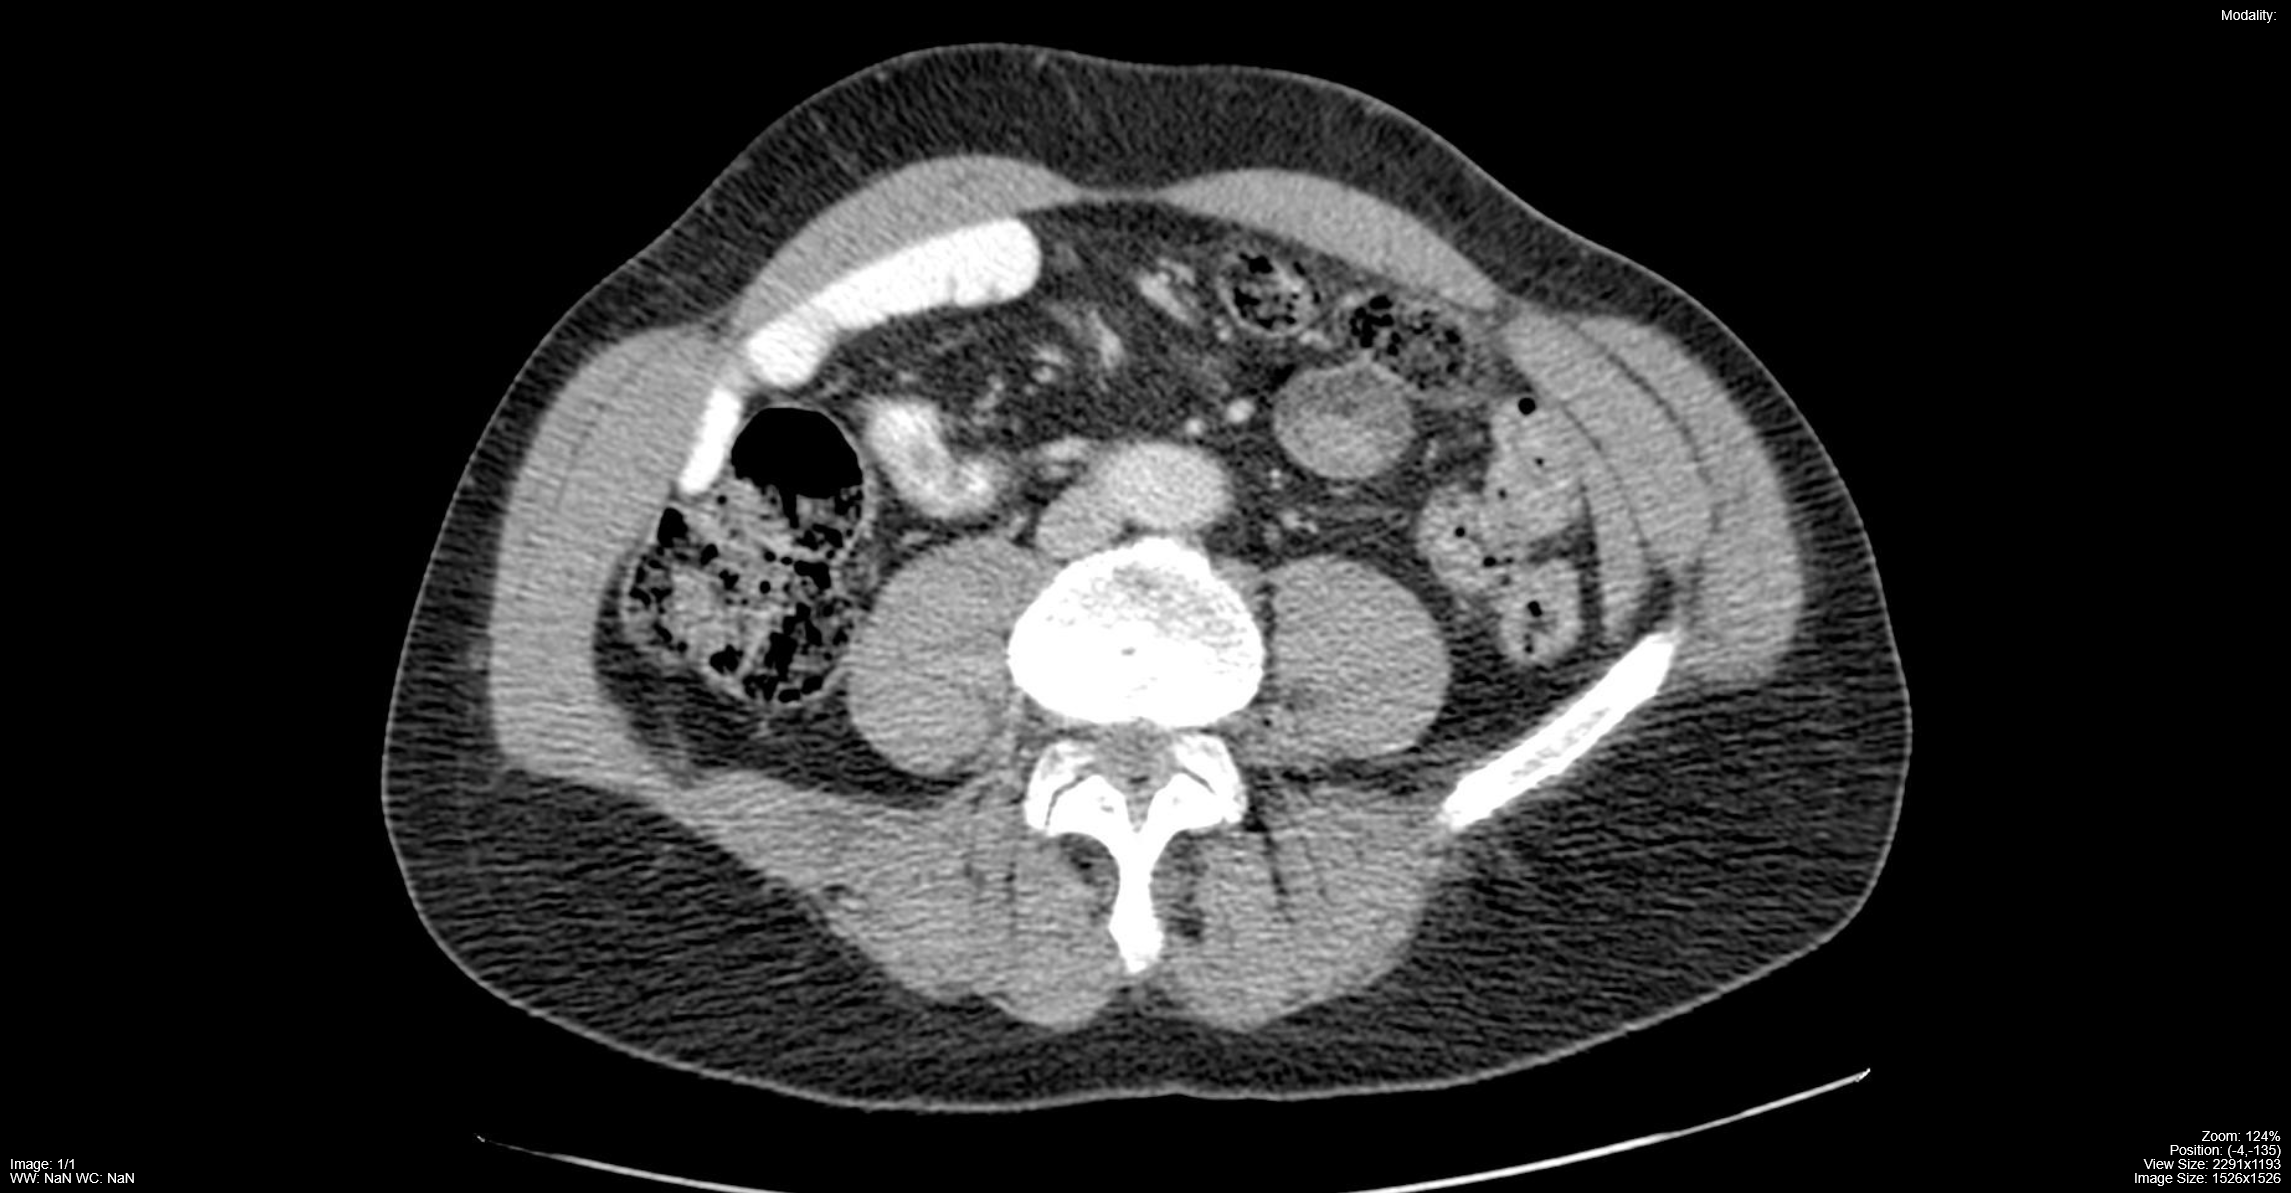

Image size: 2291x1193


In [13]:
# importing image from Github to Colab
from PIL import Image
import requests
import io
url = "https://raw.githubusercontent.com/ryanlin3124/Pytorch-exercises/refs/heads/main/imaging-exercises/abdomenCT_2.png"
response = requests.get(url)
# 200 is the status code for "OK"
if response.status_code == 200:
    img = Image.open(io.BytesIO(response.content))
else:
    print("Failed to download image")

display(img)
width, height = img.size
print(f"Image size: {width}x{height}")


In [15]:
# convert img to use tensors
import torchvision.transforms as transforms

transform = transforms.ToTensor()
tensor_img = transform(img)

tensor_img.dtype, tensor_img.shape

(torch.float32, torch.Size([4, 1193, 2291]))

2. Apply colormaps to the image

Apply these 4 color maps:
- Gray
- Jet
- Viridis
- Turbo

Then display it as a 2x2 img with a colorbar for each image

In [28]:
# We have to convert the tensor image back to numpy array to use matplotlib colormaps
# remove the color channel through .mean(dim=0)
numpy_img = tensor_img.mean(dim=0).numpy()
numpy_img.shape, numpy_img.dtype

((1193, 2291), dtype('float32'))

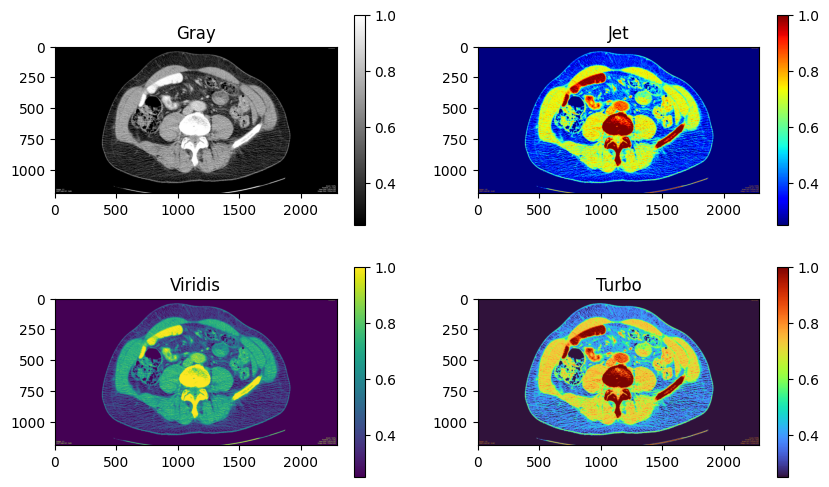

In [40]:
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(2,2,figsize = (10,6))
ax[0,0].imshow(numpy_img, cmap = "gray")
fig.colorbar(ax[0,0].imshow(numpy_img, cmap = "gray"), ax = ax[0,0])
ax[0,0].title.set_text("Gray")

ax[0,1].imshow(numpy_img, cmap = "jet")
fig.colorbar(ax[0,1].imshow(numpy_img,cmap = "jet"), ax=ax[0,1])
ax[0,1].title.set_text("Jet")

ax[1,0].imshow(numpy_img, cmap = "viridis")
fig.colorbar(ax[1,0].imshow(numpy_img,cmap = "viridis"), ax=ax[1,0])
ax[1,0].title.set_text("Viridis")

ax[1,1].imshow(numpy_img, cmap = "turbo")
fig.colorbar(ax[1,1].imshow(numpy_img,cmap = "turbo"), ax=ax[1,1])
ax[1,1].title.set_text("Turbo")


3. Display color range using histograms

Rescale the image to have a minimum of 125 and maximum of 2500


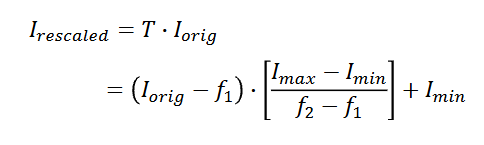


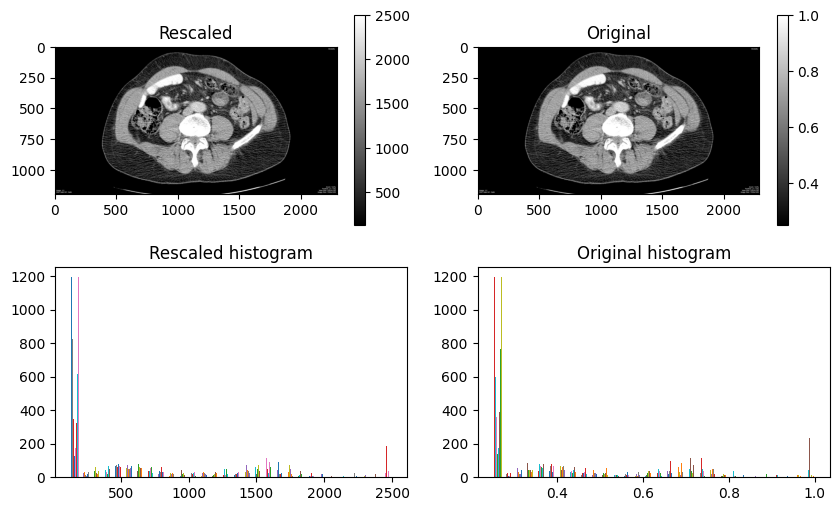

In [48]:
# Find the min-max intensity of the image
min_val = numpy_img.min()
max_val = numpy_img.max()
f1, f2 = min_val, max_val
new_max, new_min = 2500, 125
img_rescaled = (numpy_img - f1) * (new_max - new_min)/(f2 - f1) + new_min

fig, ax = plt.subplots(2,2,figsize = (10, 6))
ax[0,0].imshow(img_rescaled, cmap = "gray")
fig.colorbar(ax[0,0].imshow(img_rescaled, cmap = "gray"), ax = ax[0,0])
ax[0,0].title.set_text("Rescaled")

ax[0,1].imshow(numpy_img, cmap = "gray")
fig.colorbar(ax[0,1].imshow(numpy_img, cmap = "gray"), ax = ax[0,1])
ax[0,1].title.set_text("Original")

ax[1,0].hist(img_rescaled, bins = 30, range = (new_min, new_max))
ax[1,0].title.set_text("Rescaled histogram")

ax[1,1].hist(numpy_img, bins = 30, range = (f1, f2))
ax[1,1].title.set_text("Original histogram")


4. Apply DCT to the image

Best to use scipy as they have dct library rather than something like Pytorch, since we could just convert final result to tensor if needed

GOAL: set lowest 10% to 0

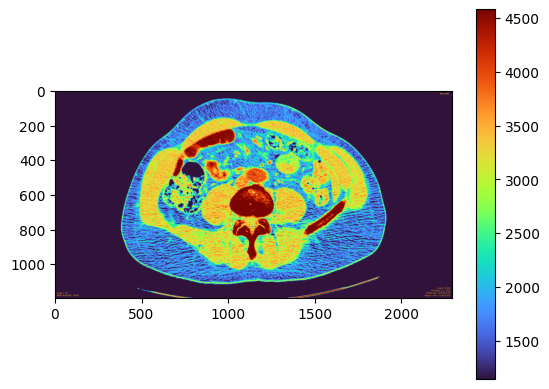

In [66]:
from scipy.fftpack import dct, idct
dct_img = dct(numpy_img)

# find the 10th percentile
# have to use abs here
thres = np.percentile(abs(dct_img), 10)
dct_img[abs(dct_img) < thres] = 0

idct_img = idct(dct_img)
im = plt.imshow(idct_img, cmap = "turbo")
plt.colorbar(im)